# NEURON | Stellar Intelligence
### Machine Learning-Based Stellar Classification

## 1. Introduction

NEURON is a machine learning project that explores the classification of stars based on their observable properties. The project uses stellar measurements to identify and classify stars into four major categories:

- **Main Sequence**
- **Giant**
- **Supergiant**
- **White Dwarf**

The classification system uses two astronomical features:

- **Color Index (B−V):** Represents the difference between a star's blue and visual magnitudes and provides an indication of its surface temperature.
- **Absolute Magnitude:** Represents the intrinsic brightness of a star, allowing stars to be compared independently of their distance from Earth.

A Random Forest Classifier is trained using these measurements to predict the stellar category of a star.

## Project Objectives

1. Explore and understand the stellar dataset.
2. Clean and prepare the data for machine learning.
3. Perform exploratory data analysis and visualize stellar distributions.
4. Identify relationships between stellar properties and classifications.
5. Train a Random Forest classification model.
6. Evaluate the model using appropriate classification metrics.
7. Analyze feature importance and test predictions on sample stars.

**Dataset:** HYG Star Database  
**Algorithm:** Random Forest Classifier  
**Input Features:** Color Index and Absolute Magnitude  
**Target:** Stellar Classification

## 2. Importing Libraries

The following Python libraries are used for data manipulation, visualization, statistical analysis, and machine learning.

In [4]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File and directory management
import os
from pathlib import Path

# Machine learning
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Dataset Loading and Initial Inspection

The dataset used in this project is the HYG Star Database (version 4.4), which contains astronomical information about stars.

Before preparing the data for machine learning, we will inspect its structure, dimensions, columns, and missing values to understand the information available.

In [5]:
# Load the original HYG dataset
df = pd.read_csv("data/stars-dataset.csv")

# Display dataset dimensions
print("Dataset successfully loaded!")
print("=" * 45)

print(f"Number of stars: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Display column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Display first five records
print("\nFirst Five Records:")
display(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

Dataset successfully loaded!
Number of stars: 119,614
Number of columns: 37

Dataset Columns:
['id', 'hip', 'hd', 'hr', 'gl', 'bf', 'proper', 'ra', 'dec', 'dist', 'pmra', 'pmdec', 'rv', 'mag', 'absmag', 'spect', 'ci', 'x', 'y', 'z', 'vx', 'vy', 'vz', 'rarad', 'decrad', 'pmrarad', 'pmdecrad', 'bayer', 'flam', 'con', 'comp', 'comp_primary', 'base', 'lum', 'var', 'var_min', 'var_max']

First Five Records:


,id,hip,hd,hr,gl,bf,proper,ra,dec,dist,pmra,pmdec,rv,mag,absmag,spect,ci,x,y,z,vx,vy,vz,rarad,decrad,pmrarad,pmdecrad,bayer,flam,con,comp,comp_primary,base,lum,var,var_min,var_max
0,0,NaN,NaN,NaN,NaN,NaN,Sol,0.000,0.000,0.000,0.000,0.000,0.000,-26.700,4.850,G2V,0.656,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,1,0,NaN,1.000,NaN,NaN,NaN
1,1,1.000,224700.000,NaN,NaN,NaN,NaN,0.000,1.089,219.780,-5.200,-1.880,0.000,9.100,2.390,F5,0.482,219.741,0.003,4.177,0.000,-0.000,-0.000,0.000,0.019,-0.000,-0.000,NaN,NaN,Psc,1,1,NaN,9.638,NaN,NaN,NaN
2,2,2.000,224690.000,NaN,NaN,NaN,NaN,0.000,-19.499,47.962,181.210,-0.930,0.000,9.270,5.866,K3V,0.999,45.211,0.003,-16.009,-0.000,0.000,-0.000,0.000,-0.340,0.000,-0.000,NaN,NaN,Cet,1,2,NaN,0.392,NaN,NaN,NaN
3,3,3.000,224699.000,NaN,NaN,NaN,NaN,0.000,38.859,442.478,5.240,-2.910,0.000,6.610,-1.619,B9,-0.019,344.553,0.030,277.615,0.000,0.000,-0.000,0.000,0.678,0.000,-0.000,NaN,NaN,And,1,3,NaN,386.901,NaN,NaN,NaN
4,4,4.000,224707.000,NaN,NaN,NaN,NaN,0.001,-51.894,134.228,62.850,0.160,0.000,8.060,2.421,F0V,0.370,82.836,0.012,-105.620,0.000,0.000,0.000,0.000,-0.906,0.000,0.000,NaN,NaN,Phe,1,4,NaN,9.367,NaN,NaN,NaN



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 119614 entries, 0 to 119613
Data columns (total 37 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            119614 non-null  int64  
 1   hip           117951 non-null  float64
 2   hd            98883 non-null   float64
 3   hr            9040 non-null    float64
 4   gl            3799 non-null    str    
 5   bf            3101 non-null    str    
 6   proper        549 non-null     str    
 7   ra            119614 non-null  float64
 8   dec           119614 non-null  float64
 9   dist          119614 non-null  float64
 10  pmra          119614 non-null  float64
 11  pmdec         119614 non-null  float64
 12  rv            119614 non-null  float64
 13  mag           119614 non-null  float64
 14  absmag        119614 non-null  float64
 15  spect         116566 non-null  str    
 16  ci            117724 non-null  float64
 17  x             119614 non-null  float6

proper     119065
base       118531
bayer      118075
flam       116877
bf         116513
gl         115815
var        113622
hr         110574
var_min    102623
var_max    102623
hd          20731
spect        3048
ci           1890
hip          1663
con             1
dtype: int64

## 4. Exploring Relevant Dataset Features

Although the original dataset contains 37 columns, this project focuses on three important variables: spectral classification, color index, and absolute magnitude.

These variables will help us understand the characteristics of stars and prepare the data for classification.

We will examine their values, statistical distributions, and missing records before performing data cleaning.

In [6]:
# Select the relevant columns
relevant_columns = ["spect", "ci", "absmag"]

# Display the first 10 records
print("Relevant Dataset Features:")
display(df[relevant_columns].head(10))

# Statistical summary
print("\nStatistical Summary:")
display(df[["ci", "absmag"]].describe())

# Missing values in relevant columns
print("\nMissing Values in Relevant Features:")
display(df[relevant_columns].isnull().sum())

# Number of available spectral classifications
print("\nNumber of Available Spectral Classifications:")
print(df["spect"].notna().sum())

# Most common spectral classifications
print("\nTop 20 Spectral Classifications:")
display(df["spect"].value_counts().head(20))

Relevant Dataset Features:


,spect,ci,absmag
0,G2V,0.656,4.850
1,F5,0.482,2.390
2,K3V,0.999,5.866
3,B9,-0.019,-1.619
4,F0V,0.370,2.421
5,G8III,0.902,1.494
6,M0V:,1.336,8.607
7,G0,0.740,5.828
8,M6e-M8.5e Tc,1.102,2.536
9,G5,1.067,0.473



Statistical Summary:


,ci,absmag
count,117724.000,119614.000
mean,0.711,0.990
std,0.493,4.353
min,-0.400,-16.230
25%,0.348,0.138
50%,0.616,1.494
75%,1.083,3.158
max,5.460,19.629



Missing Values in Relevant Features:


spect     3048
ci        1890
absmag       0
dtype: int64


Number of Available Spectral Classifications:
116566

Top 20 Spectral Classifications:


spect
K0       8569
G5       6021
A0       4943
F8       4366
G0       4237
F5       3860
K2       3697
K0III    3478
K5       2835
A2       2630
F0       2458
K1III    2090
F2       1999
K2III    1747
G8III    1699
F5V      1666
B9       1577
K3III    1298
F3V      1274
A0V      1111
Name: count, dtype: int64

## 5. Data Cleaning and Preparation

The original HYG dataset contains many astronomical variables, but only three are required for this classification task.

The spectral classification column (`spect`) is used to determine the target category of each star.

The following rules are applied:

| Spectral classification | Assigned category |
|---|---|
| Luminosity class I, IA, IB, IAB | Supergiant |
| Luminosity class III | Giant |
| Luminosity class V | Main Sequence |
| Spectral classifications beginning with D | White Dwarf |
| Luminosity classes II and IV | Excluded |

Ambiguous, unsupported, and incomplete classifications are excluded.

Rows with missing or invalid color index and absolute magnitude measurements are also removed.

In [7]:
# ==========================================
# 5. DATA CLEANING AND STELLAR CLASSIFICATION
# ==========================================

import re

# Create a copy of the original dataset
df_clean = df.copy()

# Function to classify stars
def classify_star(spectral_type):

    if pd.isna(spectral_type):
        return None

    spectral_type = str(spectral_type).strip().upper()
    spectral_type = re.sub(r"\s+", "", spectral_type)

    # White dwarfs
    if spectral_type.startswith("D"):
        return "White dwarf"

    # Check luminosity suffixes
    suffixes = ("IAB", "IA", "IB", "III", "II", "IV", "V", "I")

    luminosity = None

    for suffix in suffixes:
        if spectral_type.endswith(suffix):
            luminosity = suffix
            break

    if luminosity is None:
        return None

    # Reject ambiguous classifications
    previous_text = spectral_type[:-len(luminosity)]

    if re.search(
        r"(?:IAB|IA|IB|III|II|IV|V|I)[/-]$",
        previous_text
    ):
        return None

    # Classify stars
    if luminosity in ("IA", "IB", "IAB", "I"):
        return "Supergiant"

    if luminosity == "III":
        return "Giant"

    if luminosity == "V":
        return "Main sequence"

    # Exclude II and IV
    return None


# Apply classifications
df_clean["star_type"] = df_clean["spect"].apply(classify_star)

# Select required features
df_clean = df_clean[["ci", "absmag", "star_type"]].copy()

# Convert measurements to numeric values
df_clean["ci"] = pd.to_numeric(df_clean["ci"], errors="coerce")
df_clean["absmag"] = pd.to_numeric(df_clean["absmag"], errors="coerce")

# Remove missing values
df_clean.dropna(inplace=True)

# Remove infinite values
df_clean = df_clean[
    df_clean["ci"].map(lambda x: abs(x) != float("inf")) &
    df_clean["absmag"].map(lambda x: abs(x) != float("inf"))
]

# Reset index
df_clean.reset_index(drop=True, inplace=True)

# Display results
print("DATA CLEANING COMPLETED")
print("=" * 40)

print("Original records:", len(df))
print("Usable labelled stars:", len(df_clean))

print("\nStar categories:")
display(df_clean["star_type"].value_counts())

print("\nCategory percentages:")
display((df_clean["star_type"].value_counts(normalize=True) * 100).round(2))

print("\nMissing values:")
display(df_clean.isnull().sum())

print("\nCleaned dataset preview:")
display(df_clean.head())

# Save cleaned dataset
Path("outputs").mkdir(exist_ok=True)
df_clean.to_csv("outputs/cleaned_stars.csv", index=False)

print("\nSaved: outputs/cleaned_stars.csv")

DATA CLEANING COMPLETED
Original records: 119614
Usable labelled stars: 41926

Star categories:


star_type
Main sequence    22795
Giant            18029
Supergiant         865
White dwarf        237
Name: count, dtype: int64


Category percentages:


star_type
Main sequence   54.370
Giant           43.000
Supergiant       2.060
White dwarf      0.570
Name: proportion, dtype: float64


Missing values:


ci           0
absmag       0
star_type    0
dtype: int64


Cleaned dataset preview:


,ci,absmag,star_type
0,0.656,4.850,Main sequence
1,0.999,5.866,Main sequence
2,0.370,2.421,Main sequence
3,0.902,1.494,Giant
4,0.489,3.763,Main sequence



Saved: outputs/cleaned_stars.csv


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution and characteristics of the cleaned dataset before training the machine learning model.

The dataset contains four stellar categories: Main Sequence, Giant, Supergiant, and White Dwarf.

### 6.1 Distribution of Stellar Categories

This visualization shows the number of stars belonging to each stellar category. It helps identify class imbalances within the dataset.

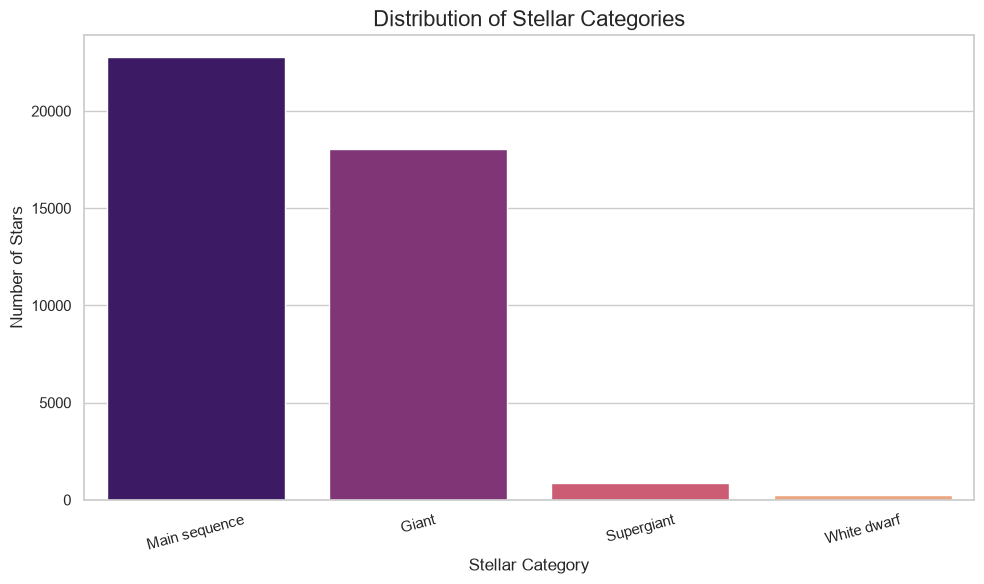

In [8]:
# Count the number of stars in each category
star_counts = df_clean["star_type"].value_counts()

# Create a bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=star_counts.index,
    y=star_counts.values,
    hue=star_counts.index,
    palette="magma",
    legend=False
)

plt.title("Distribution of Stellar Categories", fontsize=16)
plt.xlabel("Stellar Category", fontsize=12)
plt.ylabel("Number of Stars", fontsize=12)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 6.2 Distribution of Color Index (B−V)

Color Index (B−V) measures the difference between a star's blue and visual magnitudes. It provides an indication of stellar color and surface temperature.

This histogram shows how Color Index values are distributed across the dataset.

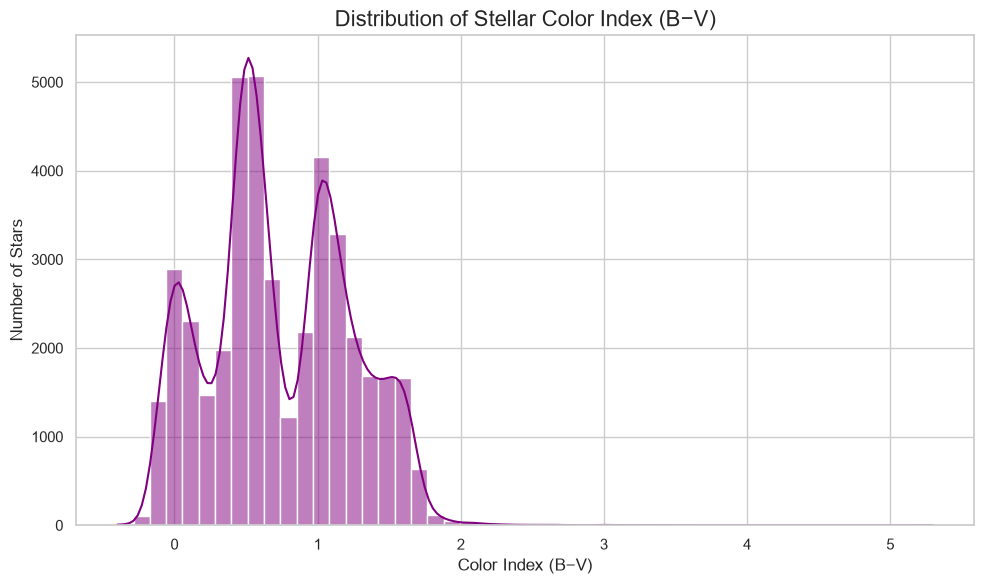

In [9]:
# Plot the distribution of Color Index
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="ci",
    bins=50,
    kde=True,
    color="purple"
)

plt.title("Distribution of Stellar Color Index (B−V)", fontsize=16)
plt.xlabel("Color Index (B−V)", fontsize=12)
plt.ylabel("Number of Stars", fontsize=12)

plt.tight_layout()
plt.show()

### 6.3 Distribution of Absolute Magnitude

Absolute Magnitude measures the intrinsic brightness of a star, independent of its distance from Earth.

This histogram illustrates the distribution of absolute magnitude values across the dataset.

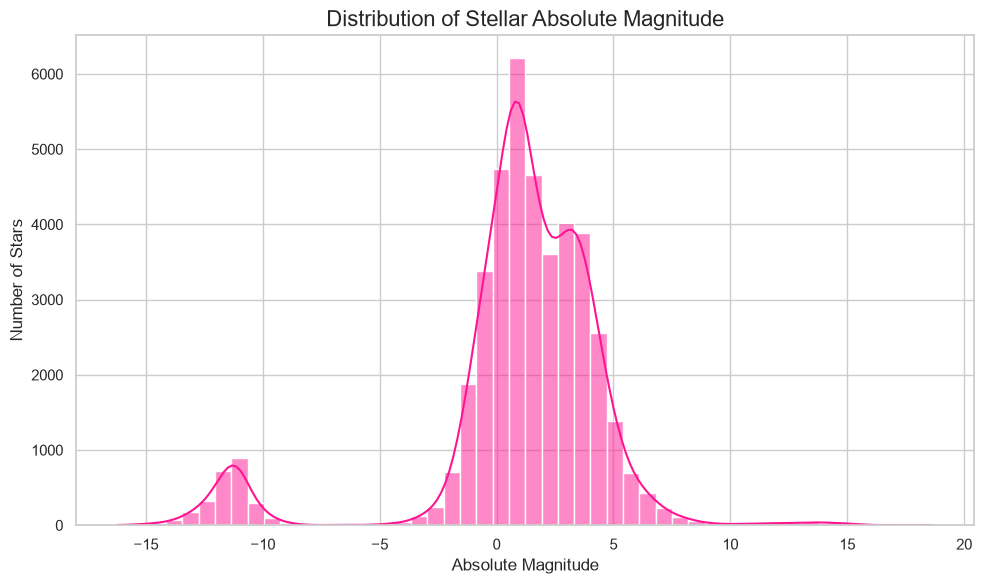

In [10]:
# Plot the distribution of Absolute Magnitude
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="absmag",
    bins=50,
    kde=True,
    color="deeppink"
)

plt.title("Distribution of Stellar Absolute Magnitude", fontsize=16)
plt.xlabel("Absolute Magnitude", fontsize=12)
plt.ylabel("Number of Stars", fontsize=12)

plt.tight_layout()
plt.show()

### 6.4 Hertzsprung–Russell (H-R) Diagram

The Hertzsprung–Russell Diagram illustrates the relationship between a star's Color Index (B−V) and Absolute Magnitude.

Each point represents an individual star, with different colors indicating its stellar classification.

The vertical axis is inverted to follow the conventional astronomical representation, where brighter stars appear toward the top of the diagram.

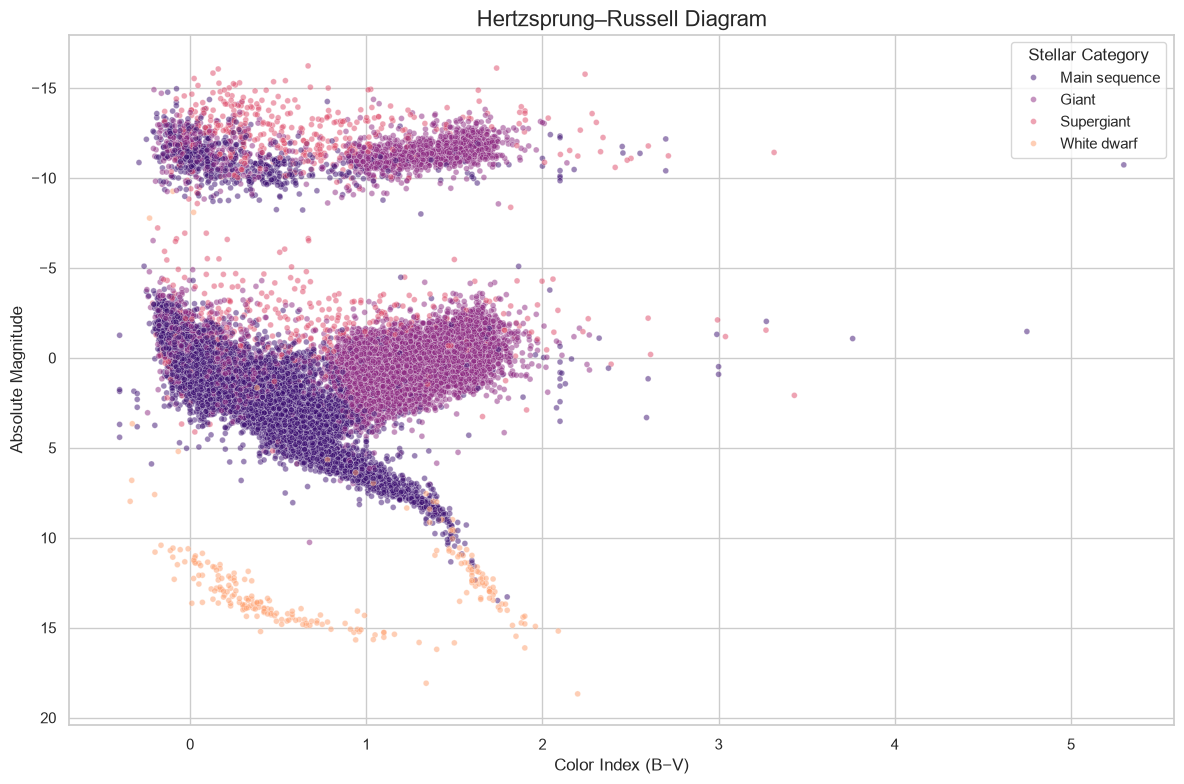

In [11]:
# Create the Hertzsprung-Russell Diagram
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df_clean,
    x="ci",
    y="absmag",
    hue="star_type",
    palette="magma",
    alpha=0.5,
    s=18
)

plt.title("Hertzsprung–Russell Diagram", fontsize=16)
plt.xlabel("Color Index (B−V)", fontsize=12)
plt.ylabel("Absolute Magnitude", fontsize=12)

# Invert the magnitude axis
plt.gca().invert_yaxis()

plt.legend(title="Stellar Category")
plt.tight_layout()
plt.show()

## 7. Preparing Data for Machine Learning

This section prepares the cleaned dataset for machine learning by separating the input features from the target variable.

The model uses two features:

- Color Index (B−V)
- Absolute Magnitude

The target variable is the stellar category, which contains four classes: Main Sequence, Giant, Supergiant, and White Dwarf.

### 7.1 Feature Selection

The input features (X) and target variable (y) are separated to prepare the dataset for model training.

In [12]:
# Select input features
X = df_clean[["ci", "absmag"]]

# Select target variable
y = df_clean["star_type"]

# Display dataset dimensions
print("FEATURES AND TARGET")
print("=" * 40)

print("Feature dimensions:", X.shape)
print("Target dimensions:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

print("\nTarget categories:")
display(y.value_counts())

FEATURES AND TARGET
Feature dimensions: (41926, 2)
Target dimensions: (41926,)

Input features:


,ci,absmag
0,0.656,4.850
1,0.999,5.866
2,0.370,2.421
3,0.902,1.494
4,0.489,3.763



Target variable:


0    Main sequence
1    Main sequence
2    Main sequence
3            Giant
4    Main sequence
Name: star_type, dtype: str


Target categories:


star_type
Main sequence    22795
Giant            18029
Supergiant         865
White dwarf        237
Name: count, dtype: int64

### 7.2 Training and Testing Split

The dataset is divided into two subsets:

- Training set (80%): Used to train the machine learning model.
- Testing set (20%): Used to evaluate its performance on unseen data.

Stratified sampling is applied to maintain the original class distribution in both subsets.

In [13]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display split dimensions
print("DATASET SPLIT")
print("=" * 40)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining set distribution:")
display(y_train.value_counts())

print("\nTesting set distribution:")
display(y_test.value_counts())

DATASET SPLIT
Training features: (33540, 2)
Testing features: (8386, 2)
Training labels: (33540,)
Testing labels: (8386,)

Training set distribution:


star_type
Main sequence    18235
Giant            14423
Supergiant         692
White dwarf        190
Name: count, dtype: int64


Testing set distribution:


star_type
Main sequence    4560
Giant            3606
Supergiant        173
White dwarf        47
Name: count, dtype: int64

## 8. Machine Learning Model Development

This section develops a Random Forest classification model to predict stellar categories based on Color Index (B−V) and Absolute Magnitude.

Random Forest is an ensemble learning algorithm that combines multiple decision trees to produce predictions. It is suitable for multi-class classification problems.

### 8.1 Training the Random Forest Classifier

The Random Forest model is configured with 200 decision trees and a maximum tree depth of 20.

Additional parameters are used to control model complexity and account for class imbalance.

In [14]:
# Initialize the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training Random Forest model...")

rf_model.fit(X_train, y_train)

print("\nMODEL TRAINING COMPLETED!")
print("=" * 40)
print("Algorithm: Random Forest")
print("Number of trees:", rf_model.n_estimators)
print("Maximum depth:", rf_model.max_depth)
print("Training samples:", len(X_train))
print("Features:", list(X.columns))
print("Classes:", list(rf_model.classes_))

Training Random Forest model...

MODEL TRAINING COMPLETED!
Algorithm: Random Forest
Number of trees: 200
Maximum depth: 20
Training samples: 33540
Features: ['ci', 'absmag']
Classes: ['Giant', 'Main sequence', 'Supergiant', 'White dwarf']


### 8.2 Model Predictions

The trained Random Forest model is used to predict the stellar categories of the testing dataset. These predictions are compared against the actual classifications to evaluate model performance.

In [15]:
# Generate predictions using the testing dataset
y_pred = rf_model.predict(X_test)

print("PREDICTIONS GENERATED")
print("=" * 40)

print("Testing samples:", len(X_test))
print("Predictions generated:", len(y_pred))

# Compare actual and predicted classifications
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(results.head(10))

PREDICTIONS GENERATED
Testing samples: 8386
Predictions generated: 8386


,Actual,Predicted
0,Giant,Giant
1,Main sequence,Main sequence
2,Giant,Giant
3,Giant,Giant
4,Main sequence,Main sequence
5,Main sequence,Main sequence
6,Main sequence,Main sequence
7,Main sequence,Main sequence
8,Main sequence,Main sequence
9,Giant,Giant


### 8.3 Model Accuracy

Accuracy measures the proportion of correctly classified stars out of all predictions made on the testing dataset.

In [16]:
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("MODEL ACCURACY")
print("=" * 40)
print(f"Accuracy: {accuracy * 100:.2f}%")

MODEL ACCURACY
Accuracy: 91.43%


### 8.4 Classification Report

The classification report evaluates the model using three metrics:

- **Precision:** How many predicted classifications were correct.
- **Recall:** How many actual stars of a category were correctly identified.
- **F1-score:** The balance between precision and recall.

These metrics provide a more detailed evaluation of the model's performance across all stellar categories.

In [17]:
# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print("=" * 60)
print(report)

CLASSIFICATION REPORT
               precision    recall  f1-score   support

        Giant       0.94      0.88      0.91      3606
Main sequence       0.91      0.96      0.93      4560
   Supergiant       0.53      0.50      0.51       173
  White dwarf       0.95      0.87      0.91        47

     accuracy                           0.91      8386
    macro avg       0.83      0.80      0.82      8386
 weighted avg       0.91      0.91      0.91      8386



### 8.5 Confusion Matrix

A confusion matrix compares the actual stellar classifications against the classifications predicted by the model.

It helps identify correctly classified stars and cases where the model incorrectly assigns a star to another category.

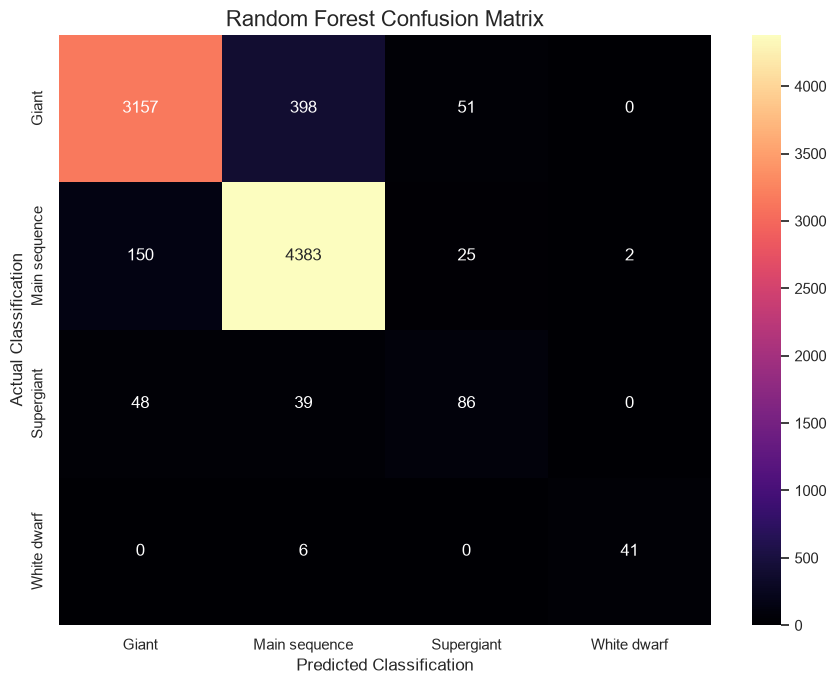

In [18]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

# Visualize confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="magma",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Random Forest Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Classification", fontsize=12)
plt.ylabel("Actual Classification", fontsize=12)

plt.tight_layout()
plt.show()

### 8.6 Feature Importance

Feature importance measures the relative contribution of each input feature to the Random Forest model's predictions.

This analysis helps identify whether Color Index (B−V) or Absolute Magnitude has a greater influence on stellar classification.

FEATURE IMPORTANCE


,Feature,Importance
1,absmag,0.679
0,ci,0.321


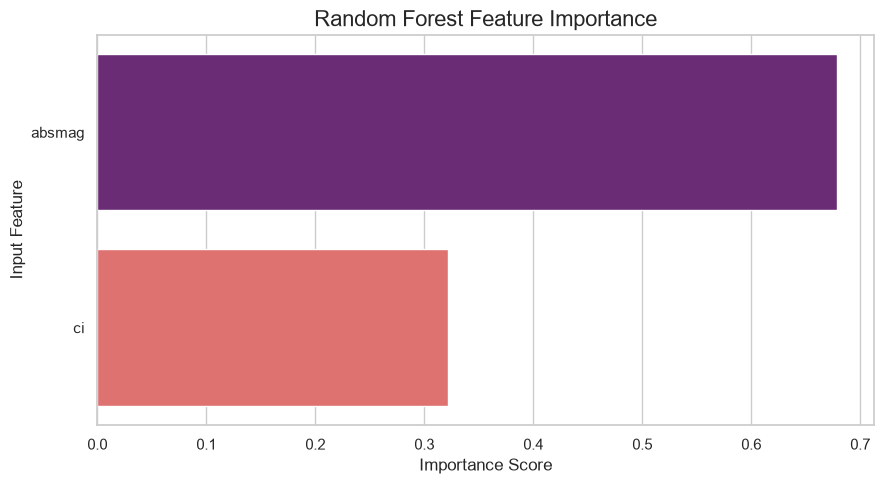

In [19]:
# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print("FEATURE IMPORTANCE")
print("=" * 40)
display(feature_importance)

# Visualize feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="magma",
    legend=False
)

plt.title("Random Forest Feature Importance", fontsize=16)
plt.xlabel("Importance Score")
plt.ylabel("Input Feature")

plt.tight_layout()
plt.show()

## 9. Final Model Training

After evaluating the model using the training and testing datasets, a final Random Forest classifier is trained using the complete cleaned dataset.

This allows the final model to learn from all available labelled star records.

### 9.1 Training the Final Model

The final model uses the same Random Forest configuration as the evaluated model, with all 41,926 cleaned star records.

In [20]:
# Initialize the final Random Forest model
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Train using the complete dataset
print("Training final model on all available data...")

final_model.fit(X, y)

print("\nFINAL MODEL TRAINING COMPLETED!")
print("=" * 40)
print("Training records:", len(X))
print("Features:", list(X.columns))
print("Number of trees:", final_model.n_estimators)
print("Classes:", list(final_model.classes_))

Training final model on all available data...

FINAL MODEL TRAINING COMPLETED!
Training records: 41926
Features: ['ci', 'absmag']
Number of trees: 200
Classes: ['Giant', 'Main sequence', 'Supergiant', 'White dwarf']


### 9.2 Saving the Final Model

The trained model is saved as a Pickle file using Joblib so it can be loaded and reused by the NEURON web application without retraining.

In [21]:
# Create models directory
Path("models").mkdir(exist_ok=True)

# Save the final model
joblib.dump(
    final_model,
    "models/star_classifier_notebook.pkl"
)

print("Final model saved successfully!")
print("Location: models/star_classifier_notebook.pkl")

Final model saved successfully!
Location: models/star_classifier_notebook.pkl


## 10. Final Model Verification

The saved model is loaded again to verify that it can be reused successfully for future stellar classification predictions.

### 10.1 Loading and Testing the Saved Model

In [22]:
# Load the saved model
loaded_model = joblib.load("models/star_classifier_notebook.pkl")

# Create a sample star for prediction
sample_star = pd.DataFrame({
    "ci": [0.65],
    "absmag": [4.8]
})

# Predict stellar category
prediction = loaded_model.predict(sample_star)

# Get prediction probabilities
probabilities = loaded_model.predict_proba(sample_star)

print("MODEL VERIFICATION")
print("=" * 40)

print("Sample Color Index:", sample_star["ci"].iloc[0])
print("Sample Absolute Magnitude:", sample_star["absmag"].iloc[0])

print("\nPredicted Stellar Category:", prediction[0])
print(f"Model Probability: {probabilities.max() * 100:.2f}%")

MODEL VERIFICATION
Sample Color Index: 0.65
Sample Absolute Magnitude: 4.8

Predicted Stellar Category: Main sequence
Model Probability: 99.73%


## 11. Conclusion

This project developed NEURON, a machine learning-based stellar classification system using astronomical data from the HYG Star Database.

The dataset originally contained 119,614 records. After preprocessing, cleaning, and classification using spectral information, 41,926 usable star records were retained.

Two astronomical features were selected for classification:

- Color Index (B−V)
- Absolute Magnitude

A Random Forest classifier was developed to classify stars into four categories: Main Sequence, Giant, Supergiant, and White Dwarf.

The model was evaluated using an 80/20 training and testing split, achieving an accuracy of **91.43%**. Additional evaluation metrics, including precision, recall, F1-score, and a confusion matrix, were used to examine its performance across individual stellar categories.

The analysis showed that the model performs particularly well when identifying Main Sequence and Giant stars, while Supergiants remain more challenging to classify due to their limited representation in the dataset.

Finally, a new Random Forest model was trained using the complete cleaned dataset of 41,926 stars and successfully saved for future use.

The project demonstrates how machine learning can be applied to astronomical data to identify patterns and support automated stellar classification.